#1. Tái hiện và cải tiến IFA (Bài toán Cross-Domain FSS (CDFSS))

In [2]:

from google.colab import drive
drive.mount('/content/drive')
!git clone -q https://github.com/niejiahao1998/IFA.git /content/IFA
!unzip -q -n /content/drive/MyDrive/BTL_IFA/btl_data.zip -d /content/IFA
!pip -q install albumentations
%cd /content/IFA
import os
d = 'dataset/LungSegmentation/masks'
for f in os.listdir(d):
    if not f.endswith('_mask.png'):
        os.rename(os.path.join(d, f), os.path.join(d, f[:-4] + '_mask.png'))
print('xong, so mask:', len(os.listdir(d)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
fatal: destination path '/content/IFA' already exists and is not an empty directory.
/content/IFA
xong, so mask: 704


##1.1. trên Chest X-Ray

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls -lh "/content/drive/MyDrive/BTL_IFA"

Mounted at /content/drive
total 4.3G
-rw------- 1 root root 4.3G Nov 23 02:49 btl_data.zip


In [ ]:
!git clone https://github.com/niejiahao1998/IFA.git /content/IFA
%cd /content/IFA
!unzip -q "/content/drive/MyDrive/BTL_IFA/btl_data.zip" -d /content/IFA
!ls /content/IFA
!ls /content/IFA/dataset/LungSegmentation
!ls /content/IFA/trained_models/lung
!ls /content/IFA/pretrained

Cloning into '/content/IFA'...
remote: Enumerating objects: 73, done.
remote: Counting objects: 100% (73/73), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 73 (delta 23), reused 64 (delta 14), pack-reused 0 (from 0)
Receiving objects: 100% (73/73), 508.36 KiB | 10.37 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/IFA
all.sh	dataset  image	      LICENSE  pretrained  test.py	   train.py
data	ifa.py	 __init__.py  model    README.md   trained_models  util
CXR_png  masks
resnet50_1shot_avg_73.96.pth  resnet50_5shot_avg_74.59.pth
resnet50.pth


In [ ]:
%cd /content/IFA

/content/IFA


In [ ]:
%cd /content/IFA
!pip -q install albumentations
import torch, cv2, albumentations
print("torch", torch.__version__, "| gpu:", torch.cuda.is_available())
print("cv2", cv2.__version__, "| albumentations", albumentations.__version__)

/content/IFA
torch 2.14.1+cu130 | gpu: True
cv2 4.14.0 | albumentations 2.0.8


### sửa lỗi tên mask
đổi tên thêm _mask cho 138 file này

In [ ]:
import os
a = sorted(os.listdir("dataset/LungSegmentation/masks"))
b = set(os.listdir("dataset/LungSegmentation/CXR_png"))
print("so mask:", len(a), "| so anh:", len(b))
print("vi du mask:", a[:3], a[-3:])
sai = [m for m in a if not m.endswith("_mask.png")]
print("mask khong ket thuc bang _mask.png:", len(sai), sai[:5])
thieu = [m for m in a if m[:-9] + ".png" not in b]
print("mask khong tim ra anh tuong ung:", len(thieu), thieu[:5])

so mask: 704 | so anh: 800
vi du mask: ['CHNCXR_0001_0_mask.png', 'CHNCXR_0002_0_mask.png', 'CHNCXR_0003_0_mask.png'] ['MCUCXR_0390_1.png', 'MCUCXR_0393_1.png', 'MCUCXR_0399_1.png']
mask khong ket thuc bang _mask.png: 138 ['MCUCXR_0001_0.png', 'MCUCXR_0002_0.png', 'MCUCXR_0003_0.png', 'MCUCXR_0004_0.png', 'MCUCXR_0005_0.png']
mask khong tim ra anh tuong ung: 138 ['MCUCXR_0001_0.png', 'MCUCXR_0002_0.png', 'MCUCXR_0003_0.png', 'MCUCXR_0004_0.png', 'MCUCXR_0005_0.png']


In [ ]:
import os
d = "dataset/LungSegmentation/masks"
n = 0
for f in os.listdir(d):
    if not f.endswith("_mask.png"):
        os.rename(os.path.join(d, f), os.path.join(d, f[:-4] + "_mask.png"))
        n += 1
print("da doi ten:", n)
a = os.listdir(d)
b = set(os.listdir("dataset/LungSegmentation/CXR_png"))
print("mask khong tim ra anh:", len([m for m in a if m[:-9] + ".png" not in b]))

da doi ten: 138
mask khong tim ra anh: 0


### chạy lại kết quả gốc
chạy 5 seed giống tác giả. bài báo ghi 74.0, chạy ra 75.19


In [ ]:
%cd /content/IFA
!python -W ignore test.py --dataset lung --data-root ./dataset --backbone resnet50 --batch-size 24 --shot 1 --refine

/content/IFA

Namespace(data_root='./dataset', dataset='lung', backbone='resnet50', refine=True, shot=1, seed=0, batch_size=24)
Evaluating model: ./trained_models/lung/resnet50_1shot_avg_73.96.pth

Params: 8.7M

Evaluating on 5 seeds.....

Run 1:
Testing mIOU: 75.86: 100% 25/25 [07:41<00:00, 18.47s/it]

Run 2:
Testing mIOU: 75.06: 100% 25/25 [07:23<00:00, 17.72s/it]

Run 3:
Testing mIOU: 75.18: 100% 25/25 [07:28<00:00, 17.92s/it]

Run 4:
Testing mIOU: 74.45: 100% 25/25 [07:25<00:00, 17.80s/it]

Run 5:
Testing mIOU: 75.41: 100% 25/25 [07:25<00:00, 17.83s/it]

********************************
Averaged mIOU on 5 seeds: 75.19
********************************



### cải tiến
model của tác giả giữ nguyên (không train lại), nhóm chỉ sửa ở lúc test:
1. TTA: cho model dự đoán 8 lần (gốc, lật ngang, phóng to 1.25, phóng to + lật, lật dọc, xoay 90, 180, 270) rồi lấy trung bình. lúc fine-tune tác giả có train với ảnh lật/xoay nhưng lúc test lại không dùng (4 góc sau nhóm có nhân đôi support bằng cách lật ngang)
2. chọn ngưỡng trên seed 10 (seed riêng, không dùng để báo cáo)
3. hậu xử lý: phổi chỉ có 2 lá và không có lỗ => giữ 2 vùng liên thông to nhất rồi lấp lỗ


In [ ]:
%%writefile /content/IFA/cai_tien2.py
# cai_tien2.py - chạy 1 seed, lưu xác suất "phổi" của nhiều kiểu TTA để sau chọn trên seed dev
#   p0 : model gốc (1 lần, 1-shot)                      -> giống test.py
#   a  : TTA 4 góc (gốc, lật ngang, phóng 1.25, phóng + lật), 1-shot
#   b  : giống a nhưng support được nhân đôi bằng cách lật ngang ("2-shot giả")
#   c  : 2-shot giả, thêm 2 góc: lật dọc, xoay 180
#   d  : 2-shot giả, thêm 2 góc: xoay 90, xoay 270
# (lúc fine-tune tác giả có dùng lật ngang/dọc + xoay 90 nên model đã quen các góc này)
import argparse, os
import numpy as np
import torch
import torch.nn.functional as F
from tqdm import tqdm
from model.IFA_matching import IFA_MatchingNet
from data.dataset import FSSDataset
from util.utils import set_seed

p = argparse.ArgumentParser()
p.add_argument('--seed', type=int, default=0)
p.add_argument('--num', type=int, default=600)
p.add_argument('--out', default='/content/drive/MyDrive/BTL_IFA/cache2')
args = p.parse_args()
os.makedirs(args.out, exist_ok=True)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

FSSDataset.initialize(img_size=400, datapath='./dataset')
loader = FSSDataset.build_dataloader('lung', 24, 4, '0', 'val', 1)
loader.dataset.num = args.num

model = IFA_MatchingNet('resnet50', refine=True)
model.load_state_dict(torch.load('./trained_models/lung/resnet50_1shot_avg_73.96.pth', map_location=dev))
model = model.to(dev).eval()


def du_doan(img_s, mask_s, img_q, k=0, lat=False, scale=1.0, hai_shot=False):
    # k: số lần xoay 90 độ, lat: lật ngang sau khi xoay, scale: phóng to
    def bien_doi(x):
        x = torch.rot90(x, k, dims=(-2, -1))
        return x.flip(-1) if lat else x
    img_s, mask_s, img_q = bien_doi(img_s), bien_doi(mask_s), bien_doi(img_q)
    if scale != 1.0:
        s = int(400 * scale)
        img_s = F.interpolate(img_s, size=(s, s), mode='bilinear', align_corners=True)
        img_q = F.interpolate(img_q, size=(s, s), mode='bilinear', align_corners=True)
        mask_s = F.interpolate(mask_s[:, None], size=(s, s), mode='nearest')[:, 0]
    if hai_shot:  # thêm 1 support nữa bằng cách lật ngang support
        out = model([img_s, img_s.flip(-1)], [mask_s, mask_s.flip(-1)], img_q, None)[0]
    else:
        out = model([img_s], [mask_s], img_q, None)[0]
    prob = out.softmax(1)[:, 1:]
    prob = F.interpolate(prob, size=(400, 400), mode='bilinear', align_corners=True)[:, 0]
    if lat:  # biến đổi ngược lại cho đúng vị trí
        prob = prob.flip(-1)
    return torch.rot90(prob, -k, dims=(-2, -1))


def iou(pred, gt):
    return np.logical_and(pred, gt).sum() / np.logical_or(pred, gt).sum() * 100


set_seed(args.seed)  # cùng seed => cùng episode như test.py
kq = {'p0': [], 'a': [], 'b': [], 'c': [], 'd': [], 'gt': []}
with torch.no_grad():
    for img_s, mask_s, img_q, mask_q, _, _, _ in tqdm(loader):
        x = (img_s[:, 0].to(dev), mask_s[:, 0].to(dev), img_q.to(dev))
        p0 = du_doan(*x)
        a = (p0 + du_doan(*x, lat=True) + du_doan(*x, scale=1.25) + du_doan(*x, lat=True, scale=1.25)) / 4
        b = (du_doan(*x, hai_shot=True) + du_doan(*x, lat=True, hai_shot=True)
             + du_doan(*x, scale=1.25, hai_shot=True) + du_doan(*x, lat=True, scale=1.25, hai_shot=True)) / 4
        c = (du_doan(*x, k=2, lat=True, hai_shot=True) + du_doan(*x, k=2, hai_shot=True)) / 2
        d = (du_doan(*x, k=1, hai_shot=True) + du_doan(*x, k=3, hai_shot=True)) / 2
        for ten, v in zip(['p0', 'a', 'b', 'c', 'd'], [p0, a, b, c, d]):
            kq[ten].append(v.half().cpu().numpy())
        kq['gt'].append(mask_q.numpy().astype(bool))

kq = {ten: np.concatenate(v) for ten, v in kq.items()}
gt = kq['gt']
print('Seed %d | goc %.2f | a %.2f | b %.2f | b+c %.2f | b+c+d %.2f' % (
    args.seed, iou(kq['p0'] > 0.5, gt), iou(kq['a'] > 0.5, gt), iou(kq['b'] > 0.5, gt),
    iou((2 * kq['b'] + kq['c']) / 3 > 0.5, gt), iou((2 * kq['b'] + kq['c'] + kq['d']) / 4 > 0.5, gt)))
np.savez_compressed('%s/seed%d.npz' % (args.out, args.seed), **kq)
print('Da luu', '%s/seed%d.npz' % (args.out, args.seed))

Writing /content/IFA/cai_tien2.py


In [ ]:
!cd /content/IFA && for s in 10 0 1 2 3 4; do python -W ignore cai_tien2.py --seed $s; done

100% 25/25 [16:27<00:00, 39.52s/it]
Seed 10 | goc 75.17 | a 76.19 | b 76.17 | b+c 76.89 | b+c+d 77.51
Da luu /content/drive/MyDrive/BTL_IFA/cache2/seed10.npz
100% 25/25 [16:46<00:00, 40.25s/it]
Seed 0 | goc 75.86 | a 76.78 | b 76.76 | b+c 77.59 | b+c+d 78.23
Da luu /content/drive/MyDrive/BTL_IFA/cache2/seed0.npz
100% 25/25 [16:52<00:00, 40.50s/it]
Seed 1 | goc 75.06 | a 75.83 | b 75.81 | b+c 76.86 | b+c+d 77.54
Da luu /content/drive/MyDrive/BTL_IFA/cache2/seed1.npz
100% 25/25 [16:49<00:00, 40.38s/it]
Seed 2 | goc 75.19 | a 76.09 | b 76.07 | b+c 76.84 | b+c+d 77.49
Da luu /content/drive/MyDrive/BTL_IFA/cache2/seed2.npz
100% 25/25 [16:41<00:00, 40.05s/it]
Seed 3 | goc 74.45 | a 75.39 | b 75.37 | b+c 76.23 | b+c+d 76.95
Da luu /content/drive/MyDrive/BTL_IFA/cache2/seed3.npz
100% 25/25 [16:34<00:00, 39.78s/it]
Seed 4 | goc 75.42 | a 76.36 | b 76.34 | b+c 77.11 | b+c+d 77.70
Da luu /content/drive/MyDrive/BTL_IFA/cache2/seed4.npz


### kết quả
ngưỡng chọn trên seed 10, báo cáo trên seed 0-4 giống tác giả

In [ ]:
import numpy as np
from scipy import ndimage
thu_muc = '/content/drive/MyDrive/BTL_IFA/cache2'

def iou(p, g): return np.logical_and(p, g).sum() / np.logical_or(p, g).sum() * 100

def hau_xu_ly(m):  # giữ 2 vùng to nhất + lấp lỗ
    nhan, n = ndimage.label(m)
    if n > 2:
        dt = ndimage.sum(m, nhan, range(1, n + 1))
        m = np.isin(nhan, np.argsort(dt)[-2:] + 1)
    return ndimage.binary_fill_holes(m)

def tta(d): return (2 * d['a'] + d['c'] + d['d']) / 4   # trung bình 8 góc nhìn

# chọn ngưỡng trên seed 10 (dev)
d = np.load(thu_muc + '/seed10.npz')
nguong = max(np.arange(0.3, 0.71, 0.05).round(2), key=lambda t: iou(tta(d) > t, d['gt']))
print('nguong chon tren seed 10:', nguong)

# kết quả trên seed 0-4
goc, moi = [], []
for s in range(5):
    d = np.load(thu_muc + '/seed%d.npz' % s)
    goc.append(iou(d['p0'] > 0.5, d['gt']))
    moi.append(iou(np.array([hau_xu_ly(m) for m in tta(d) > nguong]), d['gt']))
    print('seed %d | goc %.2f | cai tien %.2f' % (s, goc[-1], moi[-1]))
print('trung binh 5 seed | goc %.2f | cai tien %.2f' % (np.mean(goc), np.mean(moi)))

nguong chon tren seed 10: 0.55
seed 0 | goc 75.86 | cai tien 79.52
seed 1 | goc 75.06 | cai tien 78.73
seed 2 | goc 75.19 | cai tien 78.96
seed 3 | goc 74.45 | cai tien 78.22
seed 4 | goc 75.42 | cai tien 79.08
trung binh 5 seed | goc 75.20 | cai tien 78.90


trung bình 5 seed: 75.20 lên 78.90 (+3.7). so với bài báo (74.0) là +4.9.

hình minh hoạ

/content/IFA


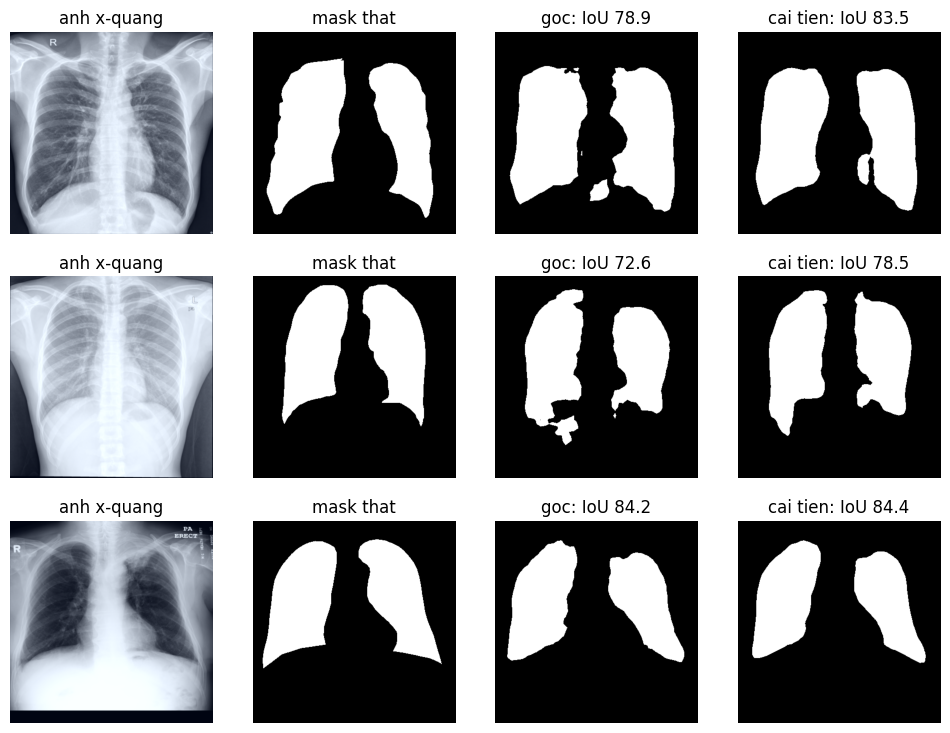

In [ ]:
%cd /content/IFA
import matplotlib.pyplot as plt
from util.utils import set_seed
from data.dataset import FSSDataset
FSSDataset.initialize(img_size=400, datapath='./dataset')
ds = FSSDataset.build_dataloader('lung', 1, 0, '0', 'val', 1).dataset

d = dict(np.load(thu_muc + '/seed0.npz'))
p = tta(d)
set_seed(0)  # cùng seed => bốc đúng các ảnh như lúc chạy
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for i in range(3):
    anh = (ds[i][2].permute(1, 2, 0).numpy() * 0.229 + 0.485).clip(0, 1)  # ảnh x-quang (bỏ chuẩn hoá)
    gt, goc, moi = d['gt'][i], d['p0'][i] > 0.5, hau_xu_ly(p[i] > nguong)
    hinh = [(anh, 'anh x-quang'), (gt, 'mask that'), (goc, 'goc: IoU %.1f' % iou(goc, gt)), (moi, 'cai tien: IoU %.1f' % iou(moi, gt))]
    for j, (h, ten) in enumerate(hinh):
        ax[i, j].imshow(h, cmap='gray'); ax[i, j].set_title(ten); ax[i, j].axis('off')
plt.show()

chạy thử model trên 1 ảnh bất kỳ (nếu cô muốn xem chạy thật)

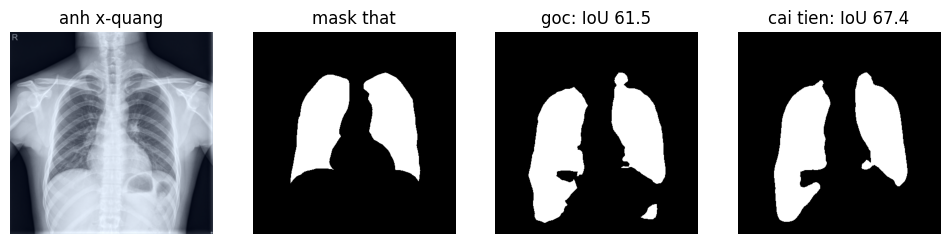

In [ ]:
# chạy thử model thật trên 1 ảnh bất kỳ (đổi so để lấy ảnh khác), khoảng 10-20 giây
import torch, torch.nn.functional as F
from model.IFA_matching import IFA_MatchingNet
model = IFA_MatchingNet('resnet50', refine=True)
model.load_state_dict(torch.load('./trained_models/lung/resnet50_1shot_avg_73.96.pth'))
model = model.cuda().eval()

def du_doan(img_s, mask_s, img_q, k=0, lat=False, scale=1.0, hai_shot=False):
    def bd(x):
        x = torch.rot90(x, k, dims=(-2, -1))
        return x.flip(-1) if lat else x
    img_s, mask_s, img_q = bd(img_s), bd(mask_s), bd(img_q)
    if scale != 1.0:
        img_s = F.interpolate(img_s, scale_factor=scale, mode='bilinear', align_corners=True)
        img_q = F.interpolate(img_q, scale_factor=scale, mode='bilinear', align_corners=True)
        mask_s = F.interpolate(mask_s[:, None], scale_factor=scale, mode='nearest')[:, 0]
    if hai_shot:
        img_s, mask_s = [img_s, img_s.flip(-1)], [mask_s, mask_s.flip(-1)]
    else:
        img_s, mask_s = [img_s], [mask_s]
    with torch.no_grad():
        prob = model(img_s, mask_s, img_q, None)[0].softmax(1)[:, 1:]
    prob = F.interpolate(prob, size=(400, 400), mode='bilinear', align_corners=True)[0, 0]
    prob = prob.flip(-1) if lat else prob
    return torch.rot90(prob, -k, dims=(-2, -1)).cpu().numpy()

# 8 góc nhìn: (xoay 90 mấy lần, lật ngang, phóng to, nhân đôi support) - giống lúc chạy
goc_nhin = [(0, False, 1, False), (0, True, 1, False), (0, False, 1.25, False), (0, True, 1.25, False),
            (2, True, 1, True), (2, False, 1, True), (1, False, 1, True), (3, False, 1, True)]

so = 7
np.random.seed(so)
img_s, mask_s, img_q, mask_q = ds[0][:4]
x = (img_s.cuda(), mask_s.cuda(), img_q[None].cuda())
goc = du_doan(*x) > 0.5
moi = hau_xu_ly(np.mean([du_doan(*x, k, l, s, h) for k, l, s, h in goc_nhin], 0) > nguong)
gt = mask_q.numpy() > 0
anh = (img_q.permute(1, 2, 0).numpy() * 0.229 + 0.485).clip(0, 1)
hinh = [(anh, 'anh x-quang'), (gt, 'mask that'), (goc, 'goc: IoU %.1f' % iou(goc, gt)), (moi, 'cai tien: IoU %.1f' % iou(moi, gt))]
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for j, (h, ten) in enumerate(hinh):
    ax[j].imshow(h, cmap='gray'); ax[j].set_title(ten); ax[j].axis('off')
plt.show()

##1.2. ISIC




tải dữ liệu ISIC 2018

In [3]:
!mkdir -p /content/IFA/dataset/ISIC
%cd /content/IFA/dataset/ISIC
!wget -q https://isic-archive.s3.amazonaws.com/challenges/2018/ISIC2018_Task1_Training_GroundTruth.zip
!wget -q https://isic-archive.s3.amazonaws.com/challenges/2018/ISIC2018_Task1-2_Training_Input.zip
!unzip -q ISIC2018_Task1_Training_GroundTruth.zip && unzip -q ISIC2018_Task1-2_Training_Input.zip
!rm *.zip
!ls; ls ISIC2018_Task1-2_Training_Input | wc -l; ls ISIC2018_Task1_Training_GroundTruth | wc -l
%cd /content/IFA

/content/IFA/dataset/ISIC
ISIC2018_Task1-2_Training_Input  ISIC2018_Task1_Training_GroundTruth
2596
2596
/content/IFA


chia ảnh theo 3 loại bệnh (script preprocess_isic.py của tác giả bị lỗi nên nhóm tự viết lại)

In [4]:
%cd /content/IFA
import csv, os, shutil
g = 'dataset/ISIC/ISIC2018_Task1-2_Training_Input'
lop = {'nevus': '1', 'seborrheic_keratosis': '2', 'melanoma': '3'}
for c in lop.values(): os.makedirs(g + '/' + c, exist_ok=True)
for ma, ten in csv.reader(open('data/isic/class_id.csv', encoding='utf-8-sig')):
    if ten in lop: shutil.move('%s/%s.jpg' % (g, ma), '%s/%s/%s.jpg' % (g, lop[ten], ma))
print({c: len(os.listdir(g + '/' + c)) for c in lop.values()})

/content/IFA
{'1': 1867, '2': 208, '3': 519}


tải model

In [5]:
!gdown -q --folder https://drive.google.com/drive/folders/1X8QhB2hd16bFLT7o9ZlDIw1oaygV1Tdz -O /content/tai_ve
!ls -R /content/tai_ve

/content/tai_ve:
deepglobe  fss	isic  lung

/content/tai_ve/deepglobe:
resnet50_1shot_avg_50.63.pth  resnet50_5shot_avg_58.76.pth

/content/tai_ve/fss:
resnet50_1shot_avg_80.08.pth  resnet50_5shot_avg_82.36.pth

/content/tai_ve/isic:
resnet50_1shot_avg_66.34.pth  resnet50_5shot_avg_69.77.pth

/content/tai_ve/lung:
resnet50_1shot_avg_73.96.pth  resnet50_5shot_avg_74.59.pth


### chạy lại kết quả gốc isic
bài báo ghi 66.3, chạy 5 seed giống tác giả

In [7]:
!mkdir -p /content/IFA/trained_models/isic && cp /content/tai_ve/isic/*.pth /content/IFA/trained_models/isic/
!cd /content/IFA && python -W ignore test.py --dataset isic --data-root ./dataset --backbone resnet50 --batch-size 24 --shot 1 --refine


Namespace(data_root='./dataset', dataset='isic', backbone='resnet50', refine=True, shot=1, seed=0, batch_size=24)
Evaluating model: ./trained_models/isic/resnet50_1shot_avg_66.34.pth

Params: 8.7M

Evaluating on 5 seeds.....

Run 1:
Testing mIOU: 71.82: 100% 25/25 [07:11<00:00, 17.24s/it]

Run 2:
Testing mIOU: 70.83: 100% 25/25 [07:05<00:00, 17.03s/it]

Run 3:
Testing mIOU: 71.32: 100% 25/25 [07:07<00:00, 17.09s/it]

Run 4:
Testing mIOU: 72.27: 100% 25/25 [07:13<00:00, 17.33s/it]

Run 5:
Testing mIOU: 72.21: 100% 25/25 [07:07<00:00, 17.09s/it]

********************************
Averaged mIOU on 5 seeds: 71.69
********************************



### cải tiến isic
hậu xử lý: giữ vùng to nhất + bao lồi (vết bệnh trên da thường là 1 mảng khá tròn). cách này chọn trên seed 10, báo cáo trên seed 0-4
với isic code tác giả tính điểm = trung bình IoU nền và IoU vết bệnh

In [15]:
%%writefile /content/IFA/isic_chay.py
# chạy model IFA gốc trên isic, lưu mask dự đoán lên drive để hậu xử lý
import sys, numpy as np, torch
from tqdm import tqdm
from model.IFA_matching import IFA_MatchingNet
from data.dataset import FSSDataset
from util.utils import set_seed
seed = int(sys.argv[1])
FSSDataset.initialize(img_size=400, datapath='./dataset')
loader = FSSDataset.build_dataloader('isic', 24, 4, '0', 'val', 1)
model = IFA_MatchingNet('resnet50', refine=True)
model.load_state_dict(torch.load('./trained_models/isic/resnet50_1shot_avg_66.34.pth'))
model = model.cuda().eval()
set_seed(seed)  # cùng seed => cùng ảnh như test.py
P, G = [], []
with torch.no_grad():
    for img_s, mask_s, img_q, mask_q, _, _, _ in tqdm(loader):
        P.append(model([img_s[:, 0].cuda()], [mask_s[:, 0].cuda()], img_q.cuda(), None)[0].argmax(1).cpu().numpy() > 0)
        G.append(mask_q.numpy() > 0)
np.savez_compressed('/content/drive/MyDrive/BTL_IFA/cache_isic/seed%d.npz' % seed, p0=np.concatenate(P), gt=np.concatenate(G))

Writing /content/IFA/isic_chay.py


In [16]:
!cd /content/IFA && for s in 0 1 2 3 4; do python -W ignore isic_chay.py $s; done

100% 25/25 [06:19<00:00, 15.19s/it]
100% 25/25 [06:19<00:00, 15.18s/it]
100% 25/25 [06:22<00:00, 15.30s/it]
100% 25/25 [06:22<00:00, 15.29s/it]
100% 25/25 [06:04<00:00, 14.57s/it]


In [17]:
import numpy as np
from scipy import ndimage
from skimage.morphology import convex_hull_image
def iou(a, b): return np.logical_and(a, b).sum() / np.logical_or(a, b).sum()
def fbiou(p, g): return (iou(p, g) + iou(~p, ~g)) / 2 * 100  # cách tính điểm của code tác giả
def hau_xu_ly(m):  # giữ vùng to nhất + bao lồi
    nhan, n = ndimage.label(m)
    if n > 1: m = nhan == np.argmax(ndimage.sum(m, nhan, range(1, n + 1))) + 1
    return convex_hull_image(m) if m.any() else m
goc, moi = [], []
for s in range(5):
    d = np.load('/content/drive/MyDrive/BTL_IFA/cache_isic/seed%d.npz' % s)
    goc.append(fbiou(d['p0'], d['gt']))
    moi.append(fbiou(np.array([hau_xu_ly(m) for m in d['p0']]), d['gt']))
    print('seed %d | goc %.2f | cai tien %.2f' % (s, goc[-1], moi[-1]))
print('trung binh 5 seed | goc %.2f | cai tien %.2f' % (np.mean(goc), np.mean(moi)))

seed 0 | goc 71.82 | cai tien 73.44
seed 1 | goc 70.83 | cai tien 73.03
seed 2 | goc 71.32 | cai tien 73.45
seed 3 | goc 72.27 | cai tien 74.86
seed 4 | goc 72.21 | cai tien 74.22
trung binh 5 seed | goc 71.69 | cai tien 73.80


=> trung bình 5 seed: 71.69 lên 73.80 (+2.1). so với bài báo (66.3) là +7.5.

hình minh hoạ kết quả(seed0)

/content/IFA


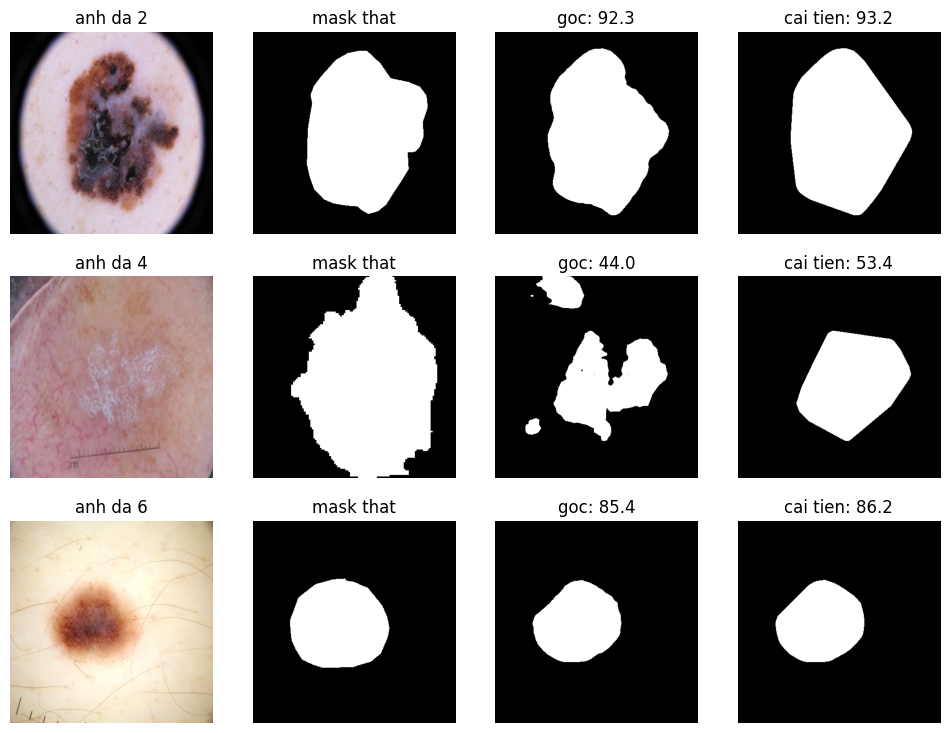

In [27]:
s = 0
chon = [2, 4, 6]
%cd /content/IFA
import matplotlib.pyplot as plt
from util.utils import set_seed
from data.dataset import FSSDataset
FSSDataset.initialize(img_size=400, datapath='./dataset')
ds = FSSDataset.build_dataloader('isic', 1, 0, '0', 'val', 1).dataset
d = np.load('/content/drive/MyDrive/BTL_IFA/cache_isic/seed%d.npz' % s)
set_seed(s)  # cùng seed => bốc đúng các ảnh như lúc chạy (phải bốc lần lượt từ ảnh 0)
anh = {}
for j in range(max(chon) + 1):
    x = ds[j]
    if j in chon: anh[j] = (x[2].permute(1, 2, 0).numpy() * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]).clip(0, 1)
fig, ax = plt.subplots(len(chon), 4, figsize=(12, 3 * len(chon)))
for i, j in enumerate(chon):
    gt, goc = d['gt'][j], d['p0'][j]
    moi = hau_xu_ly(goc)
    hinh = [(anh[j], 'anh da %d' % j), (gt, 'mask that'), (goc, 'goc: %.1f' % fbiou(goc, gt)), (moi, 'cai tien: %.1f' % fbiou(moi, gt))]
    for k, (h, ten) in enumerate(hinh):
        ax[i, k].imshow(h, cmap='gray'); ax[i, k].set_title(ten); ax[i, k].axis('off')
plt.show()

Chạy trực tiếp để lấy một kết quả

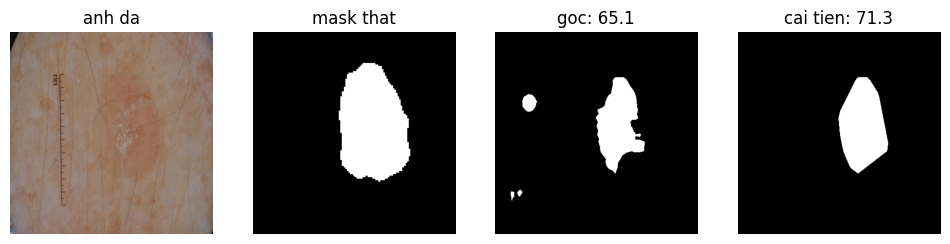

In [23]:
import torch
from model.IFA_matching import IFA_MatchingNet
model = IFA_MatchingNet('resnet50', refine=True)
model.load_state_dict(torch.load('./trained_models/isic/resnet50_1shot_avg_66.34.pth'))
model = model.cuda().eval()
so = 16
np.random.seed(so)
img_s, mask_s, img_q, mask_q = ds[so % 3][:4]
with torch.no_grad():
    goc = model([img_s.cuda()], [mask_s.cuda()], img_q[None].cuda(), None)[0].argmax(1)[0].cpu().numpy() > 0
moi = hau_xu_ly(goc)
gt = mask_q.numpy() > 0
anh = (img_q.permute(1, 2, 0).numpy() * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]).clip(0, 1)
hinh = [(anh, 'anh da'), (gt, 'mask that'), (goc, 'goc: %.1f' % fbiou(goc, gt)), (moi, 'cai tien: %.1f' % fbiou(moi, gt))]
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for j, (h, ten) in enumerate(hinh):
    ax[j].imshow(h, cmap='gray'); ax[j].set_title(ten); ax[j].axis('off')
plt.show()

## 1.3. FSS-1000 (1000 loại đồ vật)
tải dữ liệu + model

In [28]:
%cd /content/IFA/dataset
!gdown -q 16TgqOeI_0P41Eh3jWQlxlRXG9KIqtMgI -O fss.zip
!unzip -q fss.zip && rm fss.zip
!ls
!mkdir -p /content/IFA/trained_models/fss && cp /content/tai_ve/fss/*.pth /content/IFA/trained_models/fss/
%cd /content/IFA

/content/IFA/dataset
fewshot_data  ISIC  LungSegmentation
/content/IFA


In [29]:
import os
p = 'dataset/fewshot_data'
if os.path.isdir(p + '/fewshot_data'): p += '/fewshot_data'
os.rename(p, 'dataset/FSS-1000')
lop = open('data/splits/fss/test.txt').read().split('\n')[:-1]
print('so loai:', len(os.listdir('dataset/FSS-1000')), '| so loai test:', len(lop))
print('loai test bi thieu:', [c for c in lop if not os.path.isdir('dataset/FSS-1000/' + c)][:5])

so loai: 1000 | so loai test: 240
loai test bi thieu: []


### chạy lại kết quả gốc fss-1000
bài báo ghi 80.1

In [30]:
!cd /content/IFA && python -W ignore test.py --dataset fss --data-root ./dataset --backbone resnet50 --batch-size 24 --shot 1 --refine


Namespace(data_root='./dataset', dataset='fss', backbone='resnet50', refine=True, shot=1, seed=0, batch_size=24)
Evaluating model: ./trained_models/fss/resnet50_1shot_avg_80.08.pth

Params: 8.7M

Evaluating on 5 seeds.....

Run 1:
Testing mIOU: 80.90: 100% 100/100 [07:22<00:00,  4.43s/it]

Run 2:
Testing mIOU: 80.99: 100% 100/100 [07:19<00:00,  4.39s/it]

Run 3:
Testing mIOU: 81.16: 100% 100/100 [07:16<00:00,  4.37s/it]

Run 4:
Testing mIOU: 80.97: 100% 100/100 [07:16<00:00,  4.36s/it]

Run 5:
Testing mIOU: 81.06: 100% 100/100 [07:16<00:00,  4.36s/it]

********************************
Averaged mIOU on 5 seeds: 81.01
********************************



### cải tiến fss-1000
seed10

In [31]:
%%writefile /content/IFA/cai_tien_fss.py
# fss-1000: chạy model gốc + TTA 8 góc, lưu kết quả lên drive (tính điểm y hệt test.py)
import sys, os, numpy as np, torch, torch.nn.functional as F
from tqdm import tqdm
from model.IFA_matching import IFA_MatchingNet
from data.dataset import FSSDataset
from util.utils import set_seed, mIOU

seed = int(sys.argv[1])
out = '/content/drive/MyDrive/BTL_IFA/cache_fss'
os.makedirs(out, exist_ok=True)
FSSDataset.initialize(img_size=400, datapath='./dataset')
loader = FSSDataset.build_dataloader('fss', 24, 4, '0', 'val', 1)
model = IFA_MatchingNet('resnet50', refine=True)
model.load_state_dict(torch.load('./trained_models/fss/resnet50_1shot_avg_80.08.pth'))
model = model.cuda().eval()

def du_doan(img_s, mask_s, img_q, k=0, lat=False, scale=1):
    def bd(x):
        x = torch.rot90(x, k, dims=(-2, -1))
        return x.flip(-1) if lat else x
    img_s, mask_s, img_q = bd(img_s), bd(mask_s), bd(img_q)
    if scale != 1:
        img_s = F.interpolate(img_s, scale_factor=scale, mode='bilinear', align_corners=True)
        img_q = F.interpolate(img_q, scale_factor=scale, mode='bilinear', align_corners=True)
        mask_s = F.interpolate(mask_s[:, None], scale_factor=scale, mode='nearest')[:, 0]
    prob = model([img_s], [mask_s], img_q, None)[0].softmax(1)[:, 1:]
    prob = F.interpolate(prob, size=(400, 400), mode='bilinear', align_corners=True)[:, 0]
    prob = prob.flip(-1) if lat else prob
    return torch.rot90(prob, -k, dims=(-2, -1))

goc_nhin = [(0, False, 1), (0, True, 1), (0, False, 1.25), (0, True, 1.25), (2, True, 1), (2, False, 1), (1, False, 1), (3, False, 1)]

def diem(p, g, lab):  #lô 24 ảnh gán nhãn theo ảnh đầu, mIoU 1000 lớp
    m = mIOU(1000)
    for i in range(0, len(p), 24):
        m.add_batch(p[i:i + 24].astype(int) * lab[i], g[i:i + 24].astype(int) * lab[i])
    return m.evaluate() * 100

set_seed(seed)
P0, PT, GT, LAB = [], [], [], []
with torch.no_grad():
    for img_s, mask_s, img_q, mask_q, cls, _, _ in tqdm(loader):
        x = (img_s[:, 0].cuda(), mask_s[:, 0].cuda(), img_q.cuda())
        p = [du_doan(*x, k, l, s) for k, l, s in goc_nhin]
        P0.append((p[0] > 0.5).cpu().numpy())
        PT.append((sum(p) / 8 * 255).byte().cpu().numpy())
        GT.append(mask_q.numpy() > 0)
        LAB.append(cls.numpy() + 1)
P0, PT, GT, LAB = np.concatenate(P0), np.concatenate(PT), np.concatenate(GT), np.concatenate(LAB)
print('seed %d | goc %.2f | TTA %.2f' % (seed, diem(P0, GT, LAB), diem(PT > 127, GT, LAB)))
np.savez_compressed('%s/seed%d.npz' % (out, seed), p0=P0, tta=PT, gt=GT, lab=LAB)

Writing /content/IFA/cai_tien_fss.py


In [33]:
!cd /content/IFA && python -W ignore cai_tien_fss.py 10

100% 100/100 [26:17<00:00, 15.78s/it]
seed 10 | goc 81.04 | TTA 80.71


In [34]:
import numpy as np
from scipy import ndimage
from skimage.morphology import convex_hull_image
d = np.load('/content/drive/MyDrive/BTL_IFA/cache_fss/seed10.npz')
p0, pt, gt, lab = d['p0'], d['tta'], d['gt'], d['lab']

def diem(p, g, lab):  # y hệt test.py (lô 24 ảnh gán nhãn theo ảnh đầu, mIoU 1000 lớp) nhưng nhanh hơn
    h = np.zeros((1000, 1000))
    for i in range(0, len(p), 24):
        a, b, c = p[i:i + 24], g[i:i + 24], lab[i]
        h[0, 0] += (~a & ~b).sum(); h[c, c] += (a & b).sum()
        h[c, 0] += (~a & b).sum(); h[0, c] += (a & ~b).sum()
    with np.errstate(invalid='ignore'):
        return np.nanmean(np.diag(h) / (h.sum(0) + h.sum(1) - np.diag(h))) * 100
def giu(m):  # giữ vùng to nhất
    nhan, n = ndimage.label(m)
    return nhan == np.argmax(ndimage.sum(m, nhan, range(1, n + 1))) + 1 if n > 1 else m

print('goc: %.2f' % diem(p0, gt, lab))
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    print('TTA nguong %.1f: %.2f' % (t, diem(pt > t * 255, gt, lab)))
cach = {'lap lo': ndimage.binary_fill_holes,
        'giu vung to nhat': giu,
        'giu + lap lo': lambda m: ndimage.binary_fill_holes(giu(m)),
        'giu + bao loi': lambda m: convex_hull_image(giu(m)) if m.any() else m}
for ten, f in cach.items():
    print('goc + %-16s %.2f' % (ten, diem(np.array([f(m) for m in p0]), gt, lab)))

goc: 81.04
TTA nguong 0.3: 79.61
TTA nguong 0.4: 80.66
TTA nguong 0.5: 80.71
TTA nguong 0.6: 79.82
TTA nguong 0.7: 77.89
goc + lap lo           81.14
goc + giu vung to nhat 79.91
goc + giu + lap lo     80.02
goc + giu + bao loi    70.73


# 2. tổng kết
- chest x-ray: TTA 8 góc + chọn ngưỡng + giữ 2 vùng to nhất, lấp lỗ => 75.20 lên 78.90 (+3.7)
- isic: giữ vùng to nhất + bao lồi => 71.69 lên 73.80 (+2.1)


bo            bai bao  tai hien  cai tien
Chest X-Ray     74.00     75.20     78.90
ISIC            66.30     71.69     73.80
FSS-1000        80.10     81.01         -


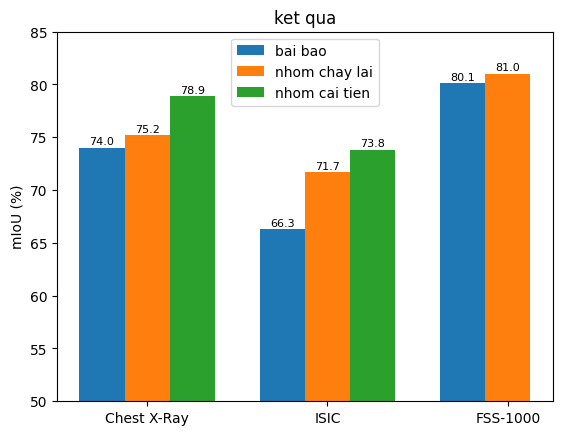

In [36]:
import numpy as np, matplotlib.pyplot as plt
bo = ['Chest X-Ray', 'ISIC', 'FSS-1000']
bai_bao  = [74.0, 66.3, 80.1]
tai_hien = [75.20, 71.69, 81.01]
cai_tien = [78.90, 73.80, np.nan]   # fss không cải tiến được
print('%-12s %8s %9s %9s' % ('bo', 'bai bao', 'tai hien', 'cai tien'))
for i in range(3):
    print('%-12s %8.2f %9.2f %9s' % (bo[i], bai_bao[i], tai_hien[i], '-' if np.isnan(cai_tien[i]) else '%.2f' % cai_tien[i]))
x = np.arange(3)
for k, (y, ten) in enumerate([(bai_bao, 'bai bao'), (tai_hien, 'nhom chay lai'), (cai_tien, 'nhom cai tien')]):
    plt.bar(x + (k - 1) * 0.25, y, 0.25, label=ten)
    for i in range(3):
        if not np.isnan(y[i]): plt.text(x[i] + (k - 1) * 0.25, y[i] + 0.3, '%.1f' % y[i], ha='center', fontsize=8)
plt.xticks(x, bo); plt.ylim(50, 85); plt.ylabel('mIoU (%)'); plt.legend()
plt.title('ket qua')
plt.show()